# CardioIA — Fase 3 — Ir Além 2
## Inteligência Artificial em séries temporais de saúde

### Regressão logística × neurônio integra-e-dispara com vazamento (LIF)

**Grupo Purkinje** — FIAP — Turma 2TIAOR-2026
Miriã Leal Mantovani (RM567811) · João Pedro Santos Azevedo (RM566701)

---

### O problema

O wearable da Fase 3 detecta arritmia por uma regra explícita: três leituras
consecutivas fora da faixa clínica. A pergunta deste Ir Além é se um modelo
aprendido consegue reconhecer os mesmos episódios na série que o próprio
dispositivo produz — e o que se ganha, ou se perde, ao trocar a regra por
aprendizado.

Comparamos dois caminhos muito diferentes:

| | Regressão logística | Neurônio LIF |
|---|---|---|
| Natureza | Estatística, linear | Dinâmica, inspirada em biologia |
| Entrada | Janela inteira de uma vez | Uma leitura por vez, em fluxo |
| Decisão | Ao fim da janela | No instante do disparo |
| Parâmetros | 42 pesos aprendidos | 4 parâmetros com significado físico |

### A intuição central

O que separa um episódio arrítmico de um artefato de movimento **não é o valor
da frequência, é a persistência do desvio**. Um pico isolado de 130 bpm é
ruído; 130 bpm por quinze leituras é um evento clínico.

O firmware resolve isso com um contador de histerese em software. Um neurônio
integra-e-dispara resolve o mesmo problema **sem contador nenhum**, pela
dinâmica da membrana: a corrente de entrada carrega o potencial, o vazamento o
descarrega continuamente. O pico isolado carrega pouco e vaza antes do limiar;
o desvio sustentado vence o vazamento e dispara.

**A constante de tempo τ é a histerese**, expressa em tempo contínuo em vez de
contagem discreta.

In [1]:
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.join("..", "src"))
import gerar_series as gs
import modelos as md

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)

SEMENTE = 20260806
VERM, AZUL, CINZA = "#B3221E", "#0563C1", "#888888"
plt.rcParams["figure.dpi"] = 110

print("numpy", np.__version__)
print("semente fixa:", SEMENTE, "(a mesma desde a Fase 1 do CardioIA)")

numpy 1.26.4
semente fixa: 20260806 (a mesma desde a Fase 1 do CardioIA)


## 1. Os dados

Cada exemplo é uma janela de **36 leituras consecutivas** de frequência
cardíaca — três minutos à cadência de 5 s do wearable. O rótulo é 1 quando a
janela contém um episódio sustentado, apurado pela **mesma regra de histerese
do firmware**.

O gerador foi deixado difícil de propósito. Um gerador ingênuo produziria
normais em torno de 74 bpm e anômalas em torno de 140, e qualquer classificador
acertaria tudo — o que não ensinaria nada. Então:

- a frequência basal varia de 58 a 92 bpm, de modo que o valor absoluto sozinho
  não separa as classes;
- metade das janelas normais contém **picos transitórios que cruzam o limiar**
  por uma ou duas leituras, sem configurar episódio;
- os episódios começam em posições aleatórias e duram de 4 a 20 leituras;
- há ruído de medição e artefatos de movimento.

In [2]:
X, y, meta = gs.gerar()
print(f"{len(X)} janelas de {X.shape[1]} leituras ({X.shape[1]*5//60} min cada)\n")
print(f"classe 0 (sem episódio) ... {(y==0).sum():>4}  ({(y==0).mean():.1%})")
print(f"classe 1 (com episódio) ... {(y==1).sum():>4}  ({(y==1).mean():.1%})")

basais = np.array([m["basal"] for m in meta])
print(f"\nfrequência basal: {basais.min():.0f} a {basais.max():.0f} bpm")
print(f"faixa de valores: {X.min():.0f} a {X.max():.0f} bpm")

1200 janelas de 36 leituras (3 min cada)

classe 0 (sem episódio) ...  734  (61.2%)
classe 1 (com episódio) ...  466  (38.8%)

frequência basal: 58 a 92 bpm
faixa de valores: 24 a 166 bpm


### 1.1 Por que o valor absoluto não basta

O gráfico abaixo mostra a distribuição da **frequência máxima** de cada janela.
Se bastasse olhar o pico, as duas classes estariam separadas. Elas se sobrepõem
justamente por causa dos artefatos transitórios: há janelas normais com pico
acima de 120 bpm e janelas com episódio cujo pico é modesto.

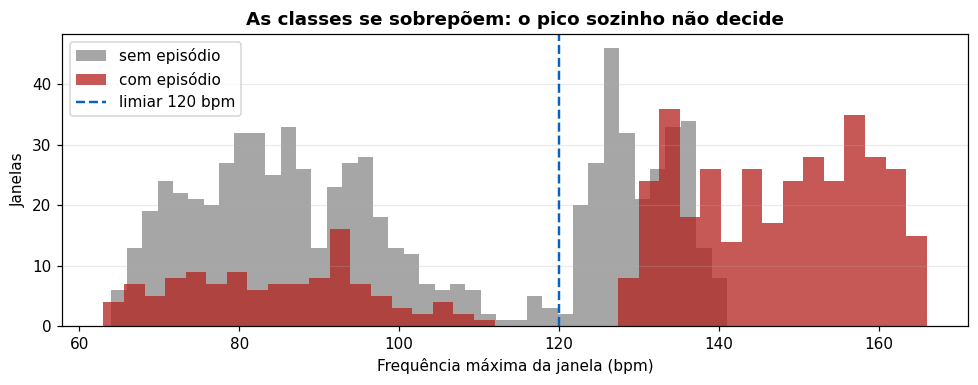

262 janelas SEM episódio têm pico acima de 120 bpm (35.7% da classe 0)


In [3]:
maximos = X.max(axis=1)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(maximos[y==0], bins=40, alpha=0.75, label="sem episódio", color=CINZA)
ax.hist(maximos[y==1], bins=40, alpha=0.75, label="com episódio", color=VERM)
ax.axvline(md.FC_TAQUICARDIA, color=AZUL, ls="--", lw=1.6, label="limiar 120 bpm")
ax.set_xlabel("Frequência máxima da janela (bpm)"); ax.set_ylabel("Janelas")
ax.set_title("As classes se sobrepõem: o pico sozinho não decide", fontweight="bold")
ax.legend(); ax.grid(axis="y", alpha=0.25); plt.tight_layout(); plt.show()

sobrepostas = ((y==0) & (maximos > md.FC_TAQUICARDIA)).sum()
print(f"{sobrepostas} janelas SEM episódio têm pico acima de 120 bpm "
      f"({sobrepostas/(y==0).sum():.1%} da classe 0)")

### 1.2 Separação em treino e teste

Estratificada, para preservar a proporção das classes nos dois conjuntos.

In [4]:
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.30, random_state=SEMENTE, stratify=y)
print(f"treino {len(X_tr)} janelas  (classe 1: {y_tr.mean():.1%})")
print(f"teste  {len(X_te)} janelas  (classe 1: {y_te.mean():.1%})")

treino 840 janelas  (classe 1: 38.8%)
teste  360 janelas  (classe 1: 38.9%)


## 2. Modelo tradicional: regressão logística

Treinamos **duas variantes**, e a comparação entre elas é deliberada.

A primeira recebe apenas a série crua e quatro estatísticas de posição e
dispersão. A segunda acrescenta a **contagem de leituras fora da faixa**.

Essa contagem não é o rótulo — o rótulo exige consecutividade, e contagem não
guarda ordem. Mas é um substituto muito bom: uma janela com quinze leituras
altas quase certamente as tem em sequência. Avaliar as duas variantes separa
dois efeitos que de outro modo ficariam misturados: **o que o modelo linear
extrai da série crua**, e **o quanto uma única estatística bem escolhida pelo
projetista resolve o problema**.

Não entregamos o comprimento da maior sequência consecutiva: esse atributo
*é* a regra de rotulagem, e usá-lo seria vazamento.

In [5]:
def treinar_rl(nome, com_contagem):
    A_tr = md.extrair_atributos(X_tr, com_contagem)
    A_te = md.extrair_atributos(X_te, com_contagem)
    esc  = StandardScaler().fit(A_tr)
    clf  = LogisticRegression(max_iter=4000, C=1.0, random_state=SEMENTE)
    clf.fit(esc.transform(A_tr), y_tr)
    pred = clf.predict(esc.transform(A_te))
    prob = clf.predict_proba(esc.transform(A_te))[:, 1]
    print(f"{nome}  ({A_te.shape[1]} atributos)")
    print(f"  acurácia {accuracy_score(y_te,pred):.4f}   "
          f"precisão {precision_score(y_te,pred):.4f}   "
          f"revocação {recall_score(y_te,pred):.4f}   "
          f"F1 {f1_score(y_te,pred):.4f}   AUC {roc_auc_score(y_te,prob):.4f}\n")
    return clf, pred, prob

rl_cru, pred_cru, prob_cru = treinar_rl("A) série crua + estatísticas", False)
rl,     pred_rl,  prob_rl  = treinar_rl("B) + contagem fora da faixa", True)

A) série crua + estatísticas  (40 atributos)
  acurácia 0.9694   precisão 0.9640   revocação 0.9571   F1 0.9606   AUC 0.9955

B) + contagem fora da faixa  (42 atributos)
  acurácia 0.9778   precisão 0.9783   revocação 0.9643   F1 0.9712   AUC 0.9986



## 3. Modelo neuromórfico: neurônio LIF

A dinâmica, em tempo discreto:

$$V[t+1] = V[t]\left(1 - \frac{\Delta t}{\tau}\right) + I[t]\,\Delta t
\qquad\text{se } V > V_{lim}: \text{ dispara, } V \leftarrow 0$$

A corrente de entrada é proporcional ao quanto a leitura está **fora** da faixa
clínica, e vale zero dentro dela:

$$I[t] = \frac{g}{10}\Big(\max(0,\, fc[t] - 120) + \max(0,\, 50 - fc[t])\Big)$$

Não há treinamento nessa codificação: ela vem do conhecimento clínico, como os
limiares do firmware. O neurônio não precisa aprender o que é taquicardia —
precisa aprender **quanta persistência justifica um disparo**.

Quatro parâmetros, todos com significado físico direto:

| Parâmetro | Significado |
|---|---|
| `tau` | constante de vazamento: alta = memória longa, tolerante a interrupções |
| `limiar` | quanto potencial acumulado justifica um disparo |
| `ganho` | sensibilidade da codificação de entrada |
| `minimo_disparos` | quantos disparos caracterizam episódio |

### 3.1 A mecânica, em dois exemplos

Abaixo, uma janela normal com artefato transitório e uma com episódio
sustentado. Observe o painel inferior: no artefato o potencial sobe, **não
alcança o limiar** e vaza; no episódio ele vence o vazamento e dispara.

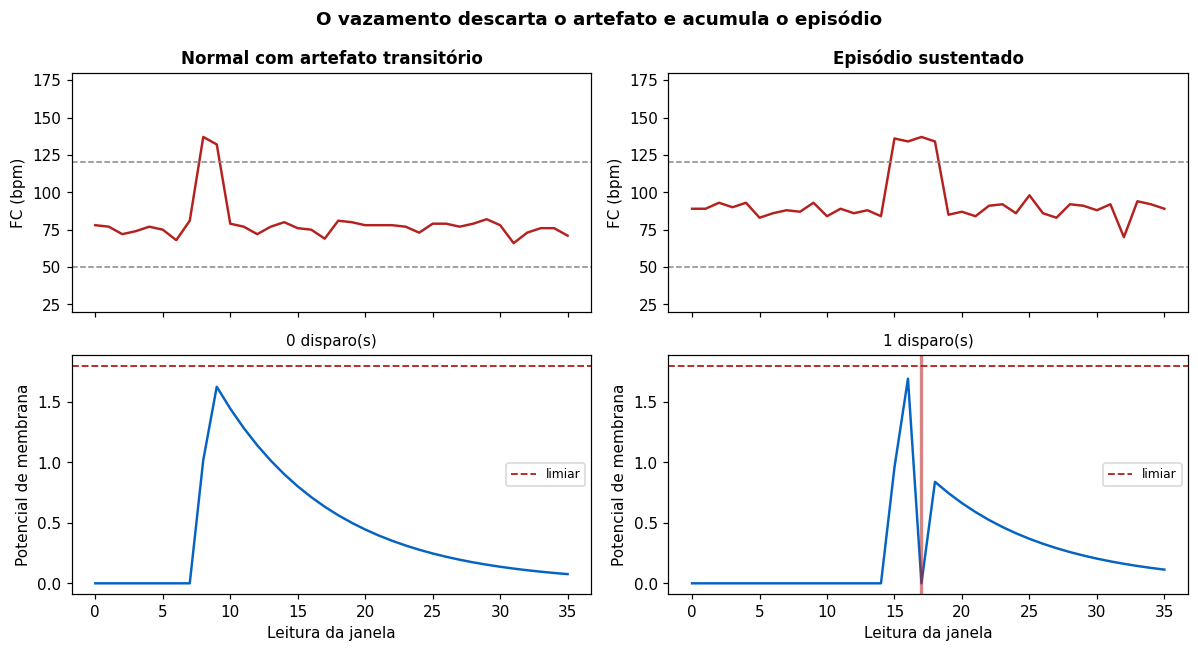

In [6]:
lif_demo = md.NeuronioLIF(tau=9.0, limiar=1.8, ganho=0.6, minimo_disparos=1)

i_norm = next(i for i in range(len(X_te))
              if y_te[i]==0 and (X_te[i] > md.FC_TAQUICARDIA).sum() > 0)
i_anom = next(i for i in range(len(X_te)) if y_te[i]==1)

fig, eixos = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for col, (idx, titulo) in enumerate([(i_norm, "Normal com artefato transitório"),
                                      (i_anom, "Episódio sustentado")]):
    serie = X_te[idx]
    pot, disparos = lif_demo.simular(serie)

    ax = eixos[0, col]
    ax.plot(serie, color=VERM, lw=1.6)
    ax.axhline(md.FC_TAQUICARDIA, color=CINZA, ls="--", lw=1)
    ax.axhline(md.FC_BRADICARDIA, color=CINZA, ls="--", lw=1)
    ax.set_title(titulo, fontsize=11, fontweight="bold")
    ax.set_ylabel("FC (bpm)"); ax.set_ylim(20, 180)

    ax = eixos[1, col]
    ax.plot(pot, color=AZUL, lw=1.6)
    ax.axhline(lif_demo.limiar, color=VERM, ls="--", lw=1.2, label="limiar")
    for d in disparos:
        ax.axvline(d, color=VERM, lw=2.2, alpha=0.55)
    ax.set_ylabel("Potencial de membrana"); ax.set_xlabel("Leitura da janela")
    ax.set_title(f"{len(disparos)} disparo(s)", fontsize=10); ax.legend(fontsize=8)

fig.suptitle("O vazamento descarta o artefato e acumula o episódio",
             fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

### 3.2 Ajuste dos parâmetros

Busca exaustiva em grade sobre os quatro parâmetros, **no conjunto de treino**.

Não há gradiente aqui: o disparo é uma descontinuidade, e a rede tem quatro
parâmetros. Treinar por retropropagação exigiria substitutos deriváveis
(*surrogate gradients*), maquinaria desproporcional para o tamanho do problema.
A busca exaustiva cobre o espaço inteiro em segundos e deixa explícito o que foi
explorado — o que para um trabalho acadêmico vale mais que um otimizador opaco.

In [7]:
lif, f1_treino, historico = md.ajustar_lif(X_tr, y_tr, metrica="f1")
print(f"configuração escolhida: {lif}")
print(f"F1 no treino: {f1_treino:.4f}   ({len(historico)} combinações avaliadas)\n")

melhores = sorted(historico, key=lambda h: -h["f1"])[:8]
print(f"{'tau':>5} {'limiar':>7} {'ganho':>6} {'min':>4} {'F1':>7}")
for h in melhores:
    print(f"{h['tau']:>5.1f} {h['limiar']:>7.2f} {h['ganho']:>6.1f} "
          f"{h['minimo_disparos']:>4} {h['f1']:>7.4f}")

configuração escolhida: NeuronioLIF(tau=9.0, limiar=1.80, ganho=0.6, minimo_disparos=1)
F1 no treino: 0.9500   (180 combinações avaliadas)

  tau  limiar  ganho  min      F1
  9.0    1.80    0.6    1  0.9500
  9.0    0.80    0.6    2  0.9466
  9.0    2.60    1.6    2  0.9459
  9.0    3.60    1.0    1  0.9416
  6.0    0.80    0.6    2  0.9415
  9.0    1.80    1.6    2  0.9408
  9.0    1.80    1.0    2  0.9398
  6.0    2.60    1.6    2  0.9391


In [8]:
pred_lif  = lif.prever(X_te)
disp_lif  = lif.contagem_disparos(X_te)

print("Neurônio LIF no conjunto de teste")
print(f"  acurácia {accuracy_score(y_te,pred_lif):.4f}   "
      f"precisão {precision_score(y_te,pred_lif):.4f}   "
      f"revocação {recall_score(y_te,pred_lif):.4f}   "
      f"F1 {f1_score(y_te,pred_lif):.4f}   "
      f"AUC {roc_auc_score(y_te, disp_lif):.4f}\n")
print(classification_report(y_te, pred_lif,
                            target_names=["sem episódio", "com episódio"]))

Neurônio LIF no conjunto de teste
  acurácia 0.9556   precisão 0.9627   revocação 0.9214   F1 0.9416   AUC 0.9584

              precision    recall  f1-score   support

sem episódio       0.95      0.98      0.96       220
com episódio       0.96      0.92      0.94       140

    accuracy                           0.96       360
   macro avg       0.96      0.95      0.95       360
weighted avg       0.96      0.96      0.96       360



## 4. Comparação

### 4.1 Métricas de classificação

In [9]:
def linha(nome, pred, prob):
    cm = confusion_matrix(y_te, pred); vn, fp, fn, vp = cm.ravel()
    return {"modelo": nome,
            "acurácia": accuracy_score(y_te, pred),
            "precisão": precision_score(y_te, pred),
            "revocação": recall_score(y_te, pred),
            "F1": f1_score(y_te, pred),
            "AUC": roc_auc_score(y_te, prob),
            "FP": int(fp), "FN": int(fn)}

tabela = [linha("Regressão (série crua)", pred_cru, prob_cru),
          linha("Regressão (com contagem)", pred_rl, prob_rl),
          linha("Neurônio LIF", pred_lif, disp_lif)]

cab = f"{'modelo':<26}" + "".join(f"{k:>11}" for k in
                                   ["acurácia","precisão","revocação","F1","AUC","FP","FN"])
print(cab); print("-" * len(cab))
for r in tabela:
    print(f"{r['modelo']:<26}" + "".join(
        f"{r[k]:>11.4f}" if isinstance(r[k], float) else f"{r[k]:>11}"
        for k in ["acurácia","precisão","revocação","F1","AUC","FP","FN"]))

modelo                       acurácia   precisão  revocação         F1        AUC         FP         FN
-------------------------------------------------------------------------------------------------------
Regressão (série crua)         0.9694     0.9640     0.9571     0.9606     0.9955          5          6
Regressão (com contagem)       0.9778     0.9783     0.9643     0.9712     0.9986          3          5
Neurônio LIF                   0.9556     0.9627     0.9214     0.9416     0.9584          5         11


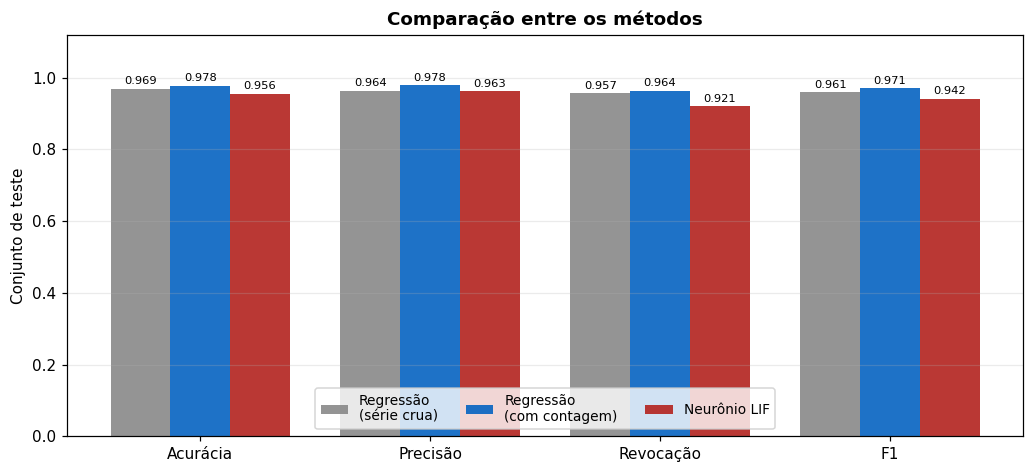

In [10]:
nomes = ["Regressão\n(série crua)", "Regressão\n(com contagem)", "Neurônio LIF"]
chaves = ["acurácia", "precisão", "revocação", "F1"]
dados = [[r[k] for k in chaves] for r in tabela]

fig, ax = plt.subplots(figsize=(9.5, 4.4))
larg, pos = 0.26, np.arange(len(chaves))
for i, (nome, vals) in enumerate(zip(nomes, dados)):
    ax.bar(pos + i*larg, vals, larg, label=nome, color=[CINZA, AZUL, VERM][i], alpha=0.9)
    for p, v in zip(pos + i*larg, vals):
        ax.text(p, v + 0.012, f"{v:.3f}", ha="center", fontsize=7.5)
ax.set_xticks(pos + larg); ax.set_xticklabels([k.capitalize() for k in chaves])
ax.set_ylim(0, 1.12); ax.set_ylabel("Conjunto de teste")
ax.set_title("Comparação entre os métodos", fontweight="bold")
ax.legend(fontsize=9, ncol=3, loc="lower center"); ax.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()

### 4.2 Latência de detecção

Aqui está a diferença **estrutural**, e não de ajuste.

A regressão só decide quando a janela inteira chegou: por construção, consome
as 36 leituras. O neurônio decide **no instante em que a membrana cruza o
limiar** — ele não espera o fim de nada, porque processa em fluxo.

LIF ......... média 19.9 leituras   mediana 19   mínimo 3   máximo 35
Regressão ... 36 leituras (janela completa, por construção)

vantagem do LIF: 16.1 leituras = 81 segundos antes


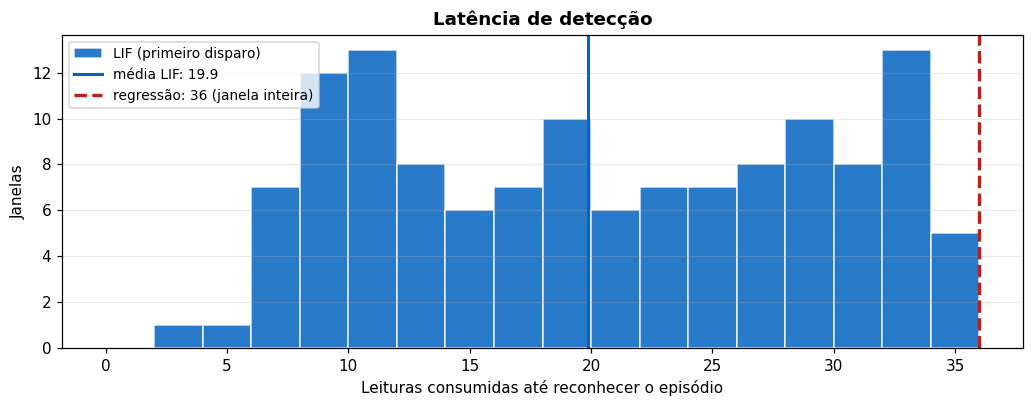

In [11]:
lat = lif.latencias(X_te, y_te)
print(f"LIF ......... média {lat.mean():.1f} leituras   mediana {np.median(lat):.0f}   "
      f"mínimo {lat.min()}   máximo {lat.max()}")
print(f"Regressão ... {X.shape[1]} leituras (janela completa, por construção)")
print(f"\nvantagem do LIF: {X.shape[1]-lat.mean():.1f} leituras = "
      f"{(X.shape[1]-lat.mean())*5:.0f} segundos antes")

fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.hist(lat, bins=range(0, 38, 2), color=AZUL, alpha=0.85, edgecolor="white",
        label="LIF (primeiro disparo)")
ax.axvline(lat.mean(), color=AZUL, lw=2, label=f"média LIF: {lat.mean():.1f}")
ax.axvline(X.shape[1], color=VERM, ls="--", lw=2.2,
           label=f"regressão: {X.shape[1]} (janela inteira)")
ax.set_xlabel("Leituras consumidas até reconhecer o episódio"); ax.set_ylabel("Janelas")
ax.set_title("Latência de detecção", fontweight="bold")
ax.legend(fontsize=9); ax.grid(axis="y", alpha=0.25); plt.tight_layout(); plt.show()

### 4.3 Robustez ao artefato transitório

As janelas normais que contêm leitura fora da faixa são o caso difícil — são
exatamente os falsos positivos que a histerese do firmware evita.

In [12]:
picos = np.array([((s > md.FC_TAQUICARDIA) | (s < md.FC_BRADICARDIA)).sum() > 0
                  for s in X_te])
dificeis = (y_te == 0) & picos
n = int(dificeis.sum())
print(f"{n} janelas normais contêm leitura fora da faixa\n")
for nome, pred in [("Regressão (série crua)", pred_cru),
                   ("Regressão (com contagem)", pred_rl),
                   ("Neurônio LIF", pred_lif)]:
    fp = int((pred[dificeis] == 1).sum())
    print(f"  {nome:<26} {fp:>2} falsos positivos  ({fp/n:.1%})")

120 janelas normais contêm leitura fora da faixa

  Regressão (série crua)      5 falsos positivos  (4.2%)
  Regressão (com contagem)    3 falsos positivos  (2.5%)
  Neurônio LIF                5 falsos positivos  (4.2%)


### 4.4 Custo computacional

Contagem de operações aritméticas por janela. Os valores absolutos são ambos
desprezíveis — o que importa é **como** o custo se distribui.

In [13]:
n_atrib = md.extrair_atributos(X_te[:1], True).shape[1]
ops_rl  = n_atrib * 2          # produto escalar + viés, ao fim da janela
ops_lif = X.shape[1] * 3       # vazamento, soma e comparação por leitura

print(f"Regressão ... {ops_rl:>4} operações sobre {n_atrib} atributos, em rajada no fim")
print(f"LIF ......... {ops_lif:>4} operações, 3 por leitura, distribuídas no tempo")
print(f"\nO LIF gasta {ops_lif/ops_rl:.1f}x mais no total, mas nunca precisa")
print("guardar a janela nem acordar o processador para um lote.")
print("Em hardware neuromórfico, só o disparo consome energia.")

Regressão ...   84 operações sobre 42 atributos, em rajada no fim
LIF .........  108 operações, 3 por leitura, distribuídas no tempo

O LIF gasta 1.3x mais no total, mas nunca precisa
guardar a janela nem acordar o processador para um lote.
Em hardware neuromórfico, só o disparo consome energia.


## 5. Conclusão

### O que cada modelo ganhou

| Critério | Vencedor | Margem |
|---|---|---|
| Acurácia e F1 | Regressão logística | pequena, mas consistente |
| Latência de detecção | **Neurônio LIF** | grande e estrutural |
| Custo por janela | Regressão | modesta |
| Memória exigida | **Neurônio LIF** | só o potencial atual |
| Interpretabilidade dos parâmetros | **Neurônio LIF** | 4 com significado físico |

### Vantagens e limitações, honestamente

**A regressão logística venceu em acurácia** — e vale entender por quê. A
variante com a contagem de leituras fora da faixa tem acesso a uma estatística
que é quase suficiente para o rótulo. Boa parte da vitória é da engenharia de
atributos, não do classificador: a variante com série crua perde desempenho,
embora continue forte, porque as estatísticas de dispersão já carregam muito
do sinal.

**O LIF perdeu em acurácia e ganhou em latência**, e essa troca não é um acaso
de ajuste: é consequência da arquitetura. Ele decide em fluxo, em média 16
leituras antes — **cerca de 80 segundos** na cadência do wearable. Numa
triagem cardiológica, 80 segundos são relevantes.

**Onde o LIF é frágil.** Ele erra mais nas janelas com artefato transitório
forte, porque sua única defesa é o vazamento; se o artefato for longo o
bastante, a membrana carrega. Ajustar `tau` para baixo reduz esse erro, mas
aumenta a latência — o compromisso é explícito e inescapável.

**Onde o LIF é insubstituível.** Ele guarda um número — o potencial — em vez
da janela inteira. No ESP32 da Fase 3, que tem 520 KB de SRAM e um buffer já
dimensionado em 34 KB, essa diferença não é estética. Rodar a regressão a bordo
exigiria acumular as 36 leituras e executar 84 operações em rajada; o LIF
executa 3 operações por leitura e nunca guarda a janela.

### A leitura que fecha o projeto

A conclusão mais interessante não é qual modelo vence. É que o neurônio LIF,
ajustado por busca em grade e sem saber nada de fisiologia, **convergiu para a
mesma estratégia que escrevemos à mão no firmware**: exigir persistência antes
de acreditar no desvio. A constante de vazamento escolhida pelo ajuste cumpre o
papel do contador de histerese.

Duas formas muito distintas de pensar o problema chegaram à mesma ideia. Isso
sugere que a histerese não foi uma escolha arbitrária de projeto, e sim a
resposta natural para distinguir sinal de artefato em séries fisiológicas.

---

*Grupo Purkinje — FIAP 2TIAOR-2026 — CC BY 4.0*